<a href="https://colab.research.google.com/github/siojzz/Practical-Statistics-for-Data-Scientists/blob/main/PracticalStatisticsChapter6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 6 - Statistical Machine Learning

This notebook contains my code reproduction and notes for Chapter 6 of *Practical Statistics for Data Scientists*.

This chapter introduces statistical machine learning methods for classification and prediction.

The main methods covered are K-Nearest Neighbors, Decision Trees, Random Forest, Boosting, and XGBoost.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier

In [2]:
!pip install xgboost

In [3]:
base = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data"

!wget -O loan200.csv "{base}/loan200.csv"
!wget -O loan3000.csv "{base}/loan3000.csv"
!wget -O loan_data.csv.gz "{base}/loan_data.csv.gz"

--2026-10-24 11:09:40--  https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/loan200.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4454 (4.3K) [text/plain]
Saving to: ‘loan200.csv’

loan200.csv         100%[===================>]   4.35K  --.-KB/s    in 0s      

2026-10-24 11:09:41 (40.0 MB/s) - ‘loan200.csv’ saved [4454/4454]

--2026-10-24 11:09:41--  https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/loan3000.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting respo

In [4]:
loan200 = pd.read_csv("loan200.csv")
loan3000 = pd.read_csv(
    "loan3000.csv",
    index_col=0
)
loan_data = pd.read_csv(
    "loan_data.csv.gz"
)

## 1. K-Nearest Neighbors

K-Nearest Neighbors (KNN) predicts an outcome by looking at observations that are most similar to a new observation.

For classification, the new observation is assigned to the class that appears most often among its K nearest neighbors.

The value K determines how many neighbors are considered.

In [5]:
predictors = [
    "payment_inc_ratio",
    "dti"
]

outcome = "outcome"

newloan = loan200.loc[
    0:0,
    predictors
]

X = loan200.loc[
    1:,
    predictors
]

y = loan200.loc[
    1:,
    outcome
]

knn = KNeighborsClassifier(
    n_neighbors=20
)

knn.fit(X, y)

knn.predict(newloan)

array(['paid off'], dtype=object)

**Interpretation:**

The KNN model looks at the 20 nearest loans to the new loan.

The majority outcome among those neighbors is used as the prediction.

## 2. Standardization

KNN uses distance to determine which observations are similar.

Variables with larger numerical scales can dominate the distance calculation.

Standardization transforms variables so that they have comparable scales.

In [6]:
predictors = [
    "payment_inc_ratio",
    "dti",
    "revol_bal",
    "revol_util"
]

outcome = "outcome"

newloan = loan_data.loc[
    0:0,
    predictors
]

X = loan_data.loc[
    1:,
    predictors
]

y = loan_data.loc[
    1:,
    outcome
]

scaler = StandardScaler()

X_std = scaler.fit_transform(X)

newloan_std = scaler.transform(
    newloan
)

knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(
    X_std,
    y
)

neighbors = knn.kneighbors(
    newloan_std
)

X.iloc[
    neighbors[1][0]
]

,payment_inc_ratio,dti,revol_bal,revol_util
2080,2.61091,1.03,1218,9.7
1438,2.34343,0.51,278,9.9
30215,2.71200,1.34,1075,8.5
28542,2.39760,0.74,2917,7.4
44737,2.34309,1.37,488,7.2


**Interpretation:**

After standardization, all predictor variables contribute more fairly to the distance calculation.

This produces neighbors that are more similar across all predictor variables.

## 3. Choosing K

The value of K affects the behavior of a KNN model.

A very small K may make the model sensitive to noise.

A larger K produces a smoother decision boundary but may ignore useful local patterns.

The best value of K can be selected by comparing predictive performance on validation data.

## 4. Tree Models

A decision tree makes predictions using a sequence of if-then rules.

The data is repeatedly divided into smaller groups using predictor values.

The final groups are called leaves, and each leaf produces a prediction.

In [7]:
predictors = [
    "borrower_score",
    "payment_inc_ratio"
]

outcome = "outcome"

X = loan3000[predictors]
y = loan3000[outcome]

loan_tree = DecisionTreeClassifier(
    random_state=1,
    criterion="entropy",
    min_impurity_decrease=0.003
)

loan_tree.fit(
    X,
    y
)

DecisionTreeClassifier(criterion='entropy', min_impurity_decrease=0.003,
                       random_state=1)

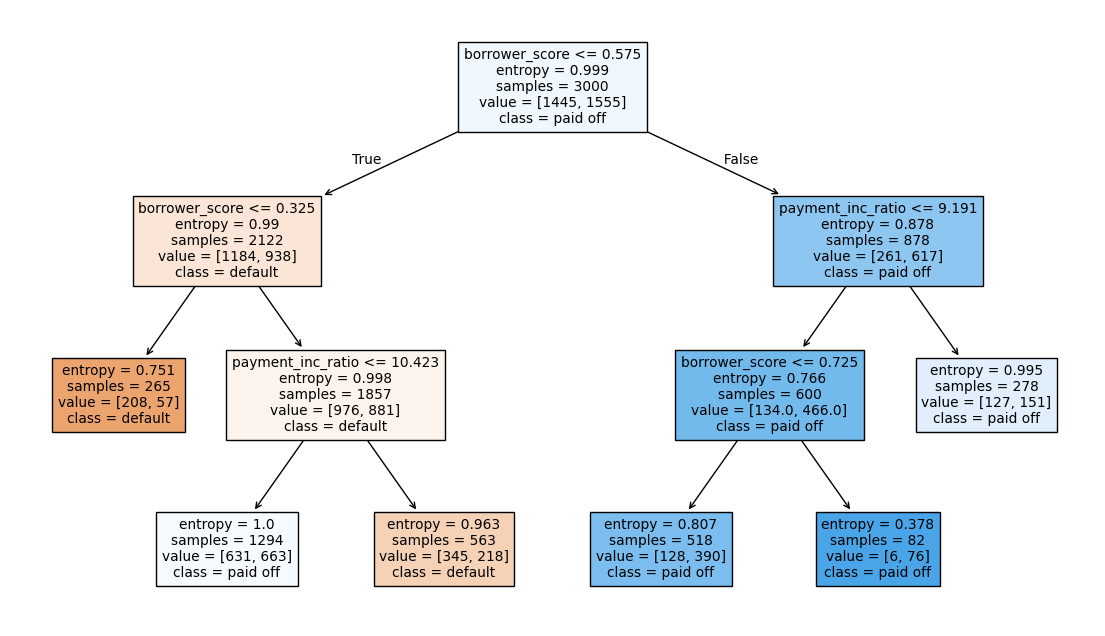

In [8]:
plt.figure(figsize=(14, 8))

plot_tree(
    loan_tree,
    feature_names=predictors,
    class_names=loan_tree.classes_,
    filled=True
)

plt.show()

**Interpretation:**

The decision tree divides the loan data using rules based on borrower score and payment-to-income ratio.

Each final leaf represents a group of observations with a predicted loan outcome.

## 5. Bagging

Bagging stands for bootstrap aggregating.

Instead of training only one model, multiple models are trained using different bootstrap samples of the original data.

The predictions from these models are then combined.

Bagging can reduce the instability of individual decision trees.

## 6. Random Forest

Random Forest extends bagging by creating many decision trees.

Each tree is trained using a bootstrap sample of observations, and only a random subset of predictor variables is considered at each split.

The final prediction combines predictions from all trees.

In [9]:
predictors = [
    "borrower_score",
    "payment_inc_ratio"
]

X = loan3000[predictors]
y = loan3000["outcome"]

rf = RandomForestClassifier(
    n_estimators=500,
    random_state=1,
    oob_score=True
)

rf.fit(
    X,
    y
)

print(
    "OOB Score:",
    rf.oob_score_
)

OOB Score: 0.5753333333333334


In [10]:
rf_predictions = rf.predict(X)

rf_predictions[:10]

array(['paid off', 'default', 'paid off', 'paid off', 'default',
       'paid off', 'default', 'paid off', 'paid off', 'paid off'],
      dtype=object)

**Interpretation:**

Random Forest combines predictions from many decision trees.

Using many trees generally produces more stable predictions than relying on one individual decision tree.

### 6.1 Feature Importance

Random Forest can estimate how important each predictor is for making predictions.

A predictor with higher feature importance contributes more to the decisions made by the trees.

In [11]:
importance = pd.DataFrame({
    "Feature": predictors,
    "Importance": rf.feature_importances_
})

importance.sort_values(
    "Importance",
    ascending=False
)

,Feature,Importance
1,payment_inc_ratio,0.879084
0,borrower_score,0.120916


## 7. Boosting

Boosting combines many weak models sequentially.

Each new model focuses more on observations that previous models predicted poorly.

The predictions from all models are combined to create a stronger final model.

## 8. XGBoost

XGBoost is an efficient implementation of gradient boosting.

It creates multiple decision trees sequentially and uses each new tree to improve previous predictions.

Important parameters include learning rate, tree depth, number of estimators, and subsampling.

In [13]:
y_binary = (
    loan3000[outcome] == "default"
).astype(int)

xgb.fit(
    X,
    y_binary
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [14]:
xgb_predictions = xgb.predict(X)

xgb_predictions[:10]

array([0, 1, 0, 0, 1, 0, 1, 0, 0, 0])

## 9. Regularization and Overfitting

Overfitting occurs when a model learns the training data too closely.

An overfitted model may perform very well on training data but poorly on new data.

Regularization limits model complexity and helps improve generalization.

In [15]:
X = loan3000[
    [
        "borrower_score",
        "payment_inc_ratio"
    ]
]

y = (
    loan3000["outcome"]
    == "default"
).astype(int)

train_X, valid_X, train_y, valid_y = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=1
)

xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    random_state=1
)

xgb_model.fit(
    train_X,
    train_y
)

train_accuracy = accuracy_score(
    train_y,
    xgb_model.predict(train_X)
)

valid_accuracy = accuracy_score(
    valid_y,
    xgb_model.predict(valid_X)
)

print(
    "Training Accuracy:",
    train_accuracy
)

print(
    "Validation Accuracy:",
    valid_accuracy
)

Training Accuracy: 0.6738095238095239
Validation Accuracy: 0.5977777777777777


**Interpretation:**

Comparing training and validation performance helps identify overfitting.

If training performance is much better than validation performance, the model may be learning patterns that do not generalize well to new data.

## 10. Hyperparameters and Cross-Validation

Hyperparameters control how a machine learning model is trained.

Examples include:

- Number of neighbors in KNN
- Tree depth
- Number of trees
- Learning rate
- Subsample size

Cross-validation can be used to compare different hyperparameter combinations and select settings that perform well on unseen data.

## 11. Chapter Summary

In this chapter, I learned several statistical machine learning methods for classification and prediction.

The main topics covered were:

- K-Nearest Neighbors
- Distance metrics
- Standardization
- Choosing K
- Decision Trees
- Recursive partitioning
- Bagging
- Random Forest
- Feature importance
- Boosting
- XGBoost
- Overfitting
- Regularization
- Hyperparameters
- Cross-validation

KNN makes predictions based on similar observations, while tree models divide the data using decision rules.

Random Forest and boosting improve predictive performance by combining many models.

Cross-validation and regularization are important for reducing overfitting and improving performance on new data.